In [1]:
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.style.use('fivethirtyeight')
sns.set()
plt.style.use('ggplot')
import pandas as pd
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from collections import Counter
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import VotingClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score
from sklearn.metrics import roc_auc_score, roc_curve, jaccard_score

ModuleNotFoundError: No module named 'plotly'

In [4]:

from pathlib import Path
import pandas as pd

dataset_candidates = [
    Path("data/original/kidney_disease.csv"),
    Path("../data/original/kidney_disease.csv"),
]

dataset_path = next(
    (path for path in dataset_candidates if path.is_file()),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find kidney_disease.csv. "
        "Open the project root in VS Code and check the data/original folder."
    )

df = pd.read_csv(dataset_path)
print(f"Dataset loaded from: {dataset_path}")
print(f"Dataset shape: {df.shape}")

Dataset loaded from: ../data/original/kidney_disease.csv
Dataset shape: (400, 26)


In [5]:
%pip install pandas

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [6]:

%pip install scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [7]:
df.head(10)

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd
5,5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,...,39,7800,4.4,yes,yes,no,good,yes,no,ckd
6,6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,...,36,NaN,NaN,no,no,no,good,no,no,ckd
7,7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,...,44,6900,5,no,yes,no,good,yes,no,ckd
8,8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,...,33,9600,4,yes,yes,no,good,no,yes,ckd
9,9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,...,29,12100,3.7,yes,yes,no,poor,no,yes,ckd


In [72]:
df['class'].value_counts()

Series([], Name: count, dtype: int64)

In [73]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset columns:
['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium', 'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count', 'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema', 'aanemia', 'class']

First 5 rows:


,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,NaN
1,7.0,50.0,1.020,4.0,0.0,0,1,0,0,176.0,...,38.0,6000.0,5.6,0,0,0,0,0,0,NaN
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.5,0,1,0,1,0,1,NaN
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,1,1,1,NaN
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,0,0,0,NaN


In [74]:
df.shape

(400, 25)

In [75]:
df.drop('id',axis=1, inplace=True)

KeyError: "['id'] not found in axis"

In [ ]:
print(df.columns.tolist())
print("Dataset shape:", df.shape)

['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']
Dataset shape: (400, 25)


In [ ]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [ ]:

df.columns = ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell',
              'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
              'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count',
              'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema',
              'aanemia', 'class']

In [ ]:
df.head()

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [ ]:
df.describe()

,age,blood_pressure,specific_gravity,albumin,sugar,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,haemoglobin
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  haemoglobin              3

In [ ]:

df['packed_cell_volume'] = pd.to_numeric(df['packed_cell_volume'], errors='coerce')
df['white_blood_cell_count'] = pd.to_numeric(df['white_blood_cell_count'], errors='coerce')
df['red_blood_cell_count'] = pd.to_numeric(df['red_blood_cell_count'], errors='coerce')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  haemoglobin              3

In [ ]:
df.columns

Index(['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar',
       'red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria',
       'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
       'potassium', 'haemoglobin', 'packed_cell_volume',
       'white_blood_cell_count', 'red_blood_cell_count', 'hypertension',
       'diabetes_mellitus', 'coronary_artery_disease', 'appetite',
       'peda_edema', 'aanemia', 'class'],
      dtype='object')

In [ ]:

cat_cols = [col for col in df.columns if df[col].dtype == 'object']
num_cols = [col for col in df.columns if df[col].dtype != 'object']

In [ ]:
cat_cols

['red_blood_cells',
 'pus_cell',
 'pus_cell_clumps',
 'bacteria',
 'hypertension',
 'diabetes_mellitus',
 'coronary_artery_disease',
 'appetite',
 'peda_edema',
 'aanemia',
 'class']

In [ ]:
num_cols

['age',
 'blood_pressure',
 'specific_gravity',
 'albumin',
 'sugar',
 'blood_glucose_random',
 'blood_urea',
 'serum_creatinine',
 'sodium',
 'potassium',
 'haemoglobin',
 'packed_cell_volume',
 'white_blood_cell_count',
 'red_blood_cell_count']

In [ ]:

for col in cat_cols:
    print(f"{col} has {df[col].unique()}")

red_blood_cells has [nan 'normal' 'abnormal']
pus_cell has ['normal' 'abnormal' nan]
pus_cell_clumps has ['notpresent' 'present' nan]
bacteria has ['notpresent' 'present' nan]
hypertension has ['yes' 'no' nan]
diabetes_mellitus has ['yes' 'no' ' yes' '\tno' '\tyes' nan]
coronary_artery_disease has ['no' 'yes' '\tno' nan]
appetite has ['good' 'poor' nan]
peda_edema has ['no' 'yes' nan]
aanemia has ['no' 'yes' nan]
class has ['ckd' 'ckd\t' 'notckd']


In [ ]:
print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)
print("\nData types:")
print(df.dtypes)

Categorical columns: ['red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria', 'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema', 'aanemia', 'class']
Numerical columns: ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium', 'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count']

Data types:
age                        float64
blood_pressure             float64
specific_gravity           float64
albumin                    float64
sugar                      float64
red_blood_cells              int64
pus_cell                     int64
pus_cell_clumps              int64
bacteria                     int64
blood_glucose_random       float64
blood_urea                 float64
serum_creatinine           float64
sodium                     float64
potassium                  float64
haemoglobin                float64
packed_cell_vol

In [ ]:

df['diabetes_mellitus'].replace(to_replace = {'\tno':'no', '\tyes': 'yes', ' yes':'yes'}, inplace=True)
df['coronary_artery_disease'] = df['coronary_artery_disease'].replace(to_replace = '\tno', value = 'no')
df['class'] = df['class'].replace(to_replace={'ckd\t':'ckd', 'notckd': 'not ckd'})

/var/folders/yl/f8f52wyn1534zlnmc7b5r0g00000gn/T/ipykernel_2919/2164515188.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['diabetes_mellitus'].replace(to_replace = {'\tno':'no', '\tyes': 'yes', ' yes':'yes'}, inplace=True)


In [ ]:

cols = ['diabetes_mellitus', 'coronary_artery_disease', 'class']
for col in cols:
    print(f"{col} has {df[col].unique()}")

diabetes_mellitus has [1 0]
coronary_artery_disease has [0 1]
class has [0 1]


In [ ]:

df['class'] = df['class'].map({'ckd':0, 'not ckd': 1})
df['class'] = pd.to_numeric(df['class'], errors = 'coerce')

In [ ]:

cols = ['diabetes_mellitus', 'coronary_artery_disease', 'class']
for col in cols:
    print(f"{col} has {df[col].unique()}")

diabetes_mellitus has [1 0]
coronary_artery_disease has [0 1]
class has [nan]


In [ ]:

df.isnull().sum().sort_values(ascending=False)

class                      400
potassium                    0
aanemia                      0
peda_edema                   0
appetite                     0
coronary_artery_disease      0
diabetes_mellitus            0
hypertension                 0
red_blood_cell_count         0
white_blood_cell_count       0
packed_cell_volume           0
haemoglobin                  0
age                          0
blood_pressure               0
serum_creatinine             0
blood_urea                   0
blood_glucose_random         0
bacteria                     0
pus_cell_clumps              0
pus_cell                     0
red_blood_cells              0
sugar                        0
albumin                      0
specific_gravity             0
sodium                       0
dtype: int64

In [ ]:
df[num_cols].isnull().sum()

age                       0
blood_pressure            0
specific_gravity          0
albumin                   0
sugar                     0
blood_glucose_random      0
blood_urea                0
serum_creatinine          0
sodium                    0
potassium                 0
haemoglobin               0
packed_cell_volume        0
white_blood_cell_count    0
red_blood_cell_count      0
dtype: int64

In [ ]:
df[cat_cols].isnull().sum()

red_blood_cells              0
pus_cell                     0
pus_cell_clumps              0
bacteria                     0
hypertension                 0
diabetes_mellitus            0
coronary_artery_disease      0
appetite                     0
peda_edema                   0
aanemia                      0
class                      400
dtype: int64

In [ ]:
df.head()

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,NaN
1,7.0,50.0,1.020,4.0,0.0,0,1,0,0,176.0,...,38.0,6000.0,5.6,0,0,0,0,0,0,NaN
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.5,0,1,0,1,0,1,NaN
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,1,1,1,NaN
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,0,0,0,NaN


In [ ]:
def random_sampling(feature):
    random_sample = df[feature].dropna().sample(df[feature].isna().sum())
    random_sample.index = df[df[feature].isnull()].index
    df.loc[df[feature].isnull(), feature] = random_sample

def impute_mode(feature):
    mode = df[feature].mode()[0]
    df[feature] = df[feature].fillna(mode)

In [ ]:
for col in num_cols:
    random_sampling(col)

In [ ]:
if 'id' in df.columns:
    df.drop('id', axis=1, inplace=True)

In [ ]:
df[num_cols].isnull().sum()

age                       0
blood_pressure            0
specific_gravity          0
albumin                   0
sugar                     0
blood_glucose_random      0
blood_urea                0
serum_creatinine          0
sodium                    0
potassium                 0
haemoglobin               0
packed_cell_volume        0
white_blood_cell_count    0
red_blood_cell_count      0
dtype: int64

In [ ]:
random_sampling('red_blood_cells')
random_sampling('pus_cell')

for col in cat_cols:
    impute_mode(col)

KeyError: 0

In [ ]:
df[cat_cols].isnull().sum()

red_blood_cells            0
pus_cell                   0
pus_cell_clumps            0
bacteria                   0
hypertension               0
diabetes_mellitus          0
coronary_artery_disease    0
appetite                   0
peda_edema                 0
aanemia                    0
class                      0
dtype: int64

In [ ]:
for col in cat_cols:
    print(f"{col} has {df[col].nunique()}")

red_blood_cells has 2
pus_cell has 2
pus_cell_clumps has 2
bacteria has 2
hypertension has 2
diabetes_mellitus has 2
coronary_artery_disease has 2
appetite has 2
peda_edema has 2
aanemia has 2
class has 2


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

In [ ]:
df.head()

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,0,1,0,0,176.0,...,38.0,6000.0,5.6,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.5,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,0,0,0,0


In [ ]:
X = df.drop('class', axis = 1)
y = df['class']

In [ ]:
X

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,haemoglobin,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,15.4,44.0,7800.0,5.2,1,1,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,0,1,0,0,176.0,...,11.3,38.0,6000.0,5.6,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,9.6,31.0,7500.0,4.5,0,1,0,1,0,1
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,11.2,32.0,6700.0,3.9,1,0,0,1,1,1
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,11.6,35.0,7300.0,4.6,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,55.0,80.0,1.020,0.0,0.0,1,1,0,0,140.0,...,15.7,47.0,6700.0,4.9,0,0,0,0,0,0
396,42.0,70.0,1.025,0.0,0.0,1,1,0,0,75.0,...,16.5,54.0,7800.0,6.2,0,0,0,0,0,0
397,12.0,80.0,1.020,0.0,0.0,1,1,0,0,100.0,...,15.8,49.0,6600.0,5.4,0,0,0,0,0,0
398,17.0,60.0,1.025,0.0,0.0,1,1,0,0,114.0,...,14.2,51.0,7200.0,5.9,0,0,0,0,0,0


In [ ]:
y

0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    1
399    1
Name: class, Length: 400, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test, y_train, y_test =  train_test_split(X,y, test_size = 0.2, random_state = 0)

#Baseline Approaches

# KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
y_train_pred = knn.predict(X_train)
y_prob = knn.predict_proba(X_test)[:, 1] if hasattr(knn, 'predict_proba') else None

knn_acc = accuracy_score(y_test, knn.predict(X_test))
print(f"Training Accuracy of KNN is {accuracy_score(y_train, knn.predict(X_train))}")
print(f"Testing Accuracy of KNN is {accuracy_score(y_test, knn.predict(X_test))}")
print(f"Training Precision of KNN is {precision_score(y_train, y_train_pred)}")
print(f"Training Recall of KNN is {recall_score(y_train, y_train_pred)}")
print(f"Training F1 score of KNN is {f1_score(y_train, y_train_pred)}")
print(f"Training Jaccard of KNN is {jaccard_score(y_train, y_train_pred)}")
print(f"Testing Precision of KNN is {precision_score(y_test, y_pred)}")
print(f"Testing Recall of KNN is {recall_score(y_test, y_pred)}")
print(f"Testing F1 score of KNN is {f1_score(y_test, y_pred)}")
print(f"Testing Jaccard Score of KNN is {jaccard_score(y_test, y_pred)}")
print(f"Training Roc Auc {roc_auc_score(y_train, knn.predict_proba(X_train)[:, 1]) if hasattr(knn, 'predict_proba') else None}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob) if y_prob is not None else None}")
print(f"Confusion Matrix of KNN is \n {confusion_matrix(y_test, knn.predict(X_test))}\n")
print(f"Classification Report of KNN is \n{classification_report(y_test, knn.predict(X_test))}")

Training Accuracy of KNN is 0.775
Testing Accuracy of KNN is 0.625


NameError: name 'precision_score' is not defined

In [ ]:

print("Columns:", df.columns.tolist())
print("Shape:", df.shape)
display(df.head(3))

Columns: ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium', 'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count', 'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema', 'aanemia', 'class']
Shape: (400, 25)


,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.02,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,0
1,7.0,50.0,1.02,4.0,0.0,0,1,0,0,176.0,...,38.0,6000.0,5.6,0,0,0,0,0,0,0
2,62.0,80.0,1.01,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.5,0,1,0,1,0,1,0


# Decision tree

In [76]:
print("Target values:")
print(df["class"].value_counts(dropna=False))

print("\nMissing target values:")
print(df["class"].isna().sum())

print("\nMissing values by column:")
print(df.isna().sum())

Target values:
class
NaN    400
Name: count, dtype: int64

Missing target values:
400

Missing values by column:
age                          0
blood_pressure               0
specific_gravity             0
albumin                      0
sugar                        0
red_blood_cells              0
pus_cell                     0
pus_cell_clumps              0
bacteria                     0
blood_glucose_random         0
blood_urea                   0
serum_creatinine             0
sodium                       0
potassium                    0
haemoglobin                  0
packed_cell_volume           0
white_blood_cell_count       0
red_blood_cell_count         0
hypertension                 0
diabetes_mellitus            0
coronary_artery_disease      0
appetite                     0
peda_edema                   0
aanemia                      0
class                      400
dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

path = Path("../data/kidney_disease.csv")

if path.exists():
    test_df = pd.read_csv(path)
    print("File found:", path)
    print("Shape:", test_df.shape)
    print("Columns:", test_df.columns.tolist())
    print(test_df.tail(5))
else:
    print("File not found:", path)

In [77]:
print("dtc defined:", 'dtc' in globals())
print("X_train defined:", 'X_train' in globals())
print("y_train defined:", 'y_train' in globals())
print("y_train_pred_dtc defined:", 'y_train_pred_dtc' in globals())
print("y_pred_dtc defined:", 'y_pred_dtc' in globals())

dtc defined: False
X_train defined: True
y_train defined: True
y_train_pred_dtc defined: False
y_pred_dtc defined: False


In [78]:
dtc = DecisionTreeClassifier()
dtc.fit(X_train, y_train)
y_pred_dtc = dtc.predict(X_test)
y_train_pred_dtc = dtc.predict(X_train)
y_prob_dtc = dtc.predict_proba(X_test)[:, 1] if hasattr(dtc, 'predict_proba') else None


NameError: name 'DecisionTreeClassifier' is not defined

In [ ]:
print("Columns:", df.columns.tolist())
print("Shape:", df.shape)

Columns: ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium', 'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count', 'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema', 'aanemia', 'class']
Shape: (400, 25)


In [ ]:
print(f"Training Accuracy of DTC is {accuracy_score(y_train, y_train_pred_dtc)}")
print(f"Testing Accuracy of dtc is {accuracy_score(y_test, y_pred_dtc)}")
print(f"Training Precision of dtc is {precision_score(y_train, y_train_pred_dtc)}")
print(f"Training Recall of dtc is {recall_score(y_train, y_train_pred_dtc)}")
print(f"Training F1 score of dtc is {f1_score(y_train, y_train_pred_dtc)}")
print(f"Training Jaccard of dtc is {jaccard_score(y_train, y_train_pred_dtc)}")
print(f"Testing Precision of dtc is {precision_score(y_test, y_pred_dtc)}")
print(f"Testing Recall of dtc is {recall_score(y_test, y_pred_dtc)}")
print(f"Testing F1 score of dtc is {f1_score(y_test, y_pred_dtc)}")
print(f"Testing Jaccard Score of dtc is {jaccard_score(y_test, y_pred_dtc)}")
print(f"Training Roc Auc {roc_auc_score(y_train, dtc.predict_proba(X_train)[:, 1]) if hasattr(dtc, 'predict_proba') else None}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_dtc) if y_prob_dtc is not None else None}")
print(f"Confusion Matrix of dtc is \n {confusion_matrix(y_test, dtc.predict(X_test))}\n")
print(f"Classification Report of dtc is \n{classification_report(y_test, dtc.predict(X_test))}")

NameError: name 'y_train_pred_dtc' is not defined

#Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
y_train_pred_lr = lr.predict(X_train)
y_prob_lr = lr.predict_proba(X_test)[:, 1] if hasattr(lr, 'predict_proba') else None


In [ ]:
print(f"Training Accuracy of rand is {accuracy_score(y_train, y_train_pred_lr)}")
print(f"Testing Accuracy of rand is {accuracy_score(y_test, y_pred_lr)}")
print(f"Training Precision of rand is {precision_score(y_train, y_train_pred_lr)}")
print(f"Training Recall of rand is {recall_score(y_train, y_train_pred_lr)}")
print(f"Training F1 score of rand is {f1_score(y_train, y_train_pred_lr)}")
print(f"Training Jaccard of rand is {jaccard_score(y_train, y_train_pred_lr)}")
print(f"Testing Precision of rand is {precision_score(y_test, y_pred_lr)}")
print(f"Testing Recall of rand is {recall_score(y_test, y_pred_lr)}")
print(f"Testing F1 score of rand is {f1_score(y_test, y_pred_lr)}")
print(f"Testing Jaccard Score of rand is {jaccard_score(y_test, y_pred_lr)}")
print(f"Training Roc Auc {roc_auc_score(y_train, lr.predict_proba(X_train)[:, 1]) if hasattr(lr, 'predict_proba') else None}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_lr) if y_prob_lr is not None else None}")
print(f"Confusion Matrix of rand is \n {confusion_matrix(y_test, lr.predict(X_test))}\n")
print(f"Classification Report of rand is \n{classification_report(y_test, lr.predict(X_test))}")

Training Accuracy of rand is 0.915625
Testing Accuracy of rand is 0.9125
Training Precision of rand is 0.8625954198473282
Training Recall of rand is 0.9262295081967213
Training F1 score of rand is 0.8932806324110671
Training Jaccard of rand is 0.8071428571428572
Testing Precision of rand is 0.8620689655172413
Testing Recall of rand is 0.8928571428571429
Testing F1 score of rand is 0.8771929824561403
Testing Jaccard Score of rand is 0.78125
Training Roc Auc 0.9622868024507367
Testing Roc Auc 0.945054945054945
Confusion Matrix of rand is 
 [[48  4]
 [ 3 25]]

Classification Report of rand is 
              precision    recall  f1-score   support

           0       0.94      0.92      0.93        52
           1       0.86      0.89      0.88        28

    accuracy                           0.91        80
   macro avg       0.90      0.91      0.90        80
weighted avg       0.91      0.91      0.91        80



#Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gbc = GradientBoostingClassifier()
gbc.fit(X_train, y_train) # Add this line to train the model before predicting.
y_pred_gbc = gbc.predict(X_test)
y_train_pred_gbc = gbc.predict(X_train)
y_prob_gbc = gbc.predict_proba(X_test)[:, 1] if hasattr(gbc, 'predict_proba') else None

In [ ]:
print(f"Training Accuracy of gbc is {accuracy_score(y_train, y_train_pred_gbc)}")
print(f"Testing Accuracy of gbc is {accuracy_score(y_test, y_pred_gbc)}")
print(f"Training Precision of gbc is {precision_score(y_train, y_train_pred_gbc)}")
print(f"Training Recall of gbc is {recall_score(y_train, y_train_pred_gbc)}")
print(f"Training F1 score of gbc is {f1_score(y_train, y_train_pred_gbc)}")
print(f"Training Jaccard of gbc is {jaccard_score(y_train, y_train_pred_gbc)}")
print(f"Testing Precision of gbc is {precision_score(y_test, y_pred_gbc)}")
print(f"Testing Recall of gbc is {recall_score(y_test, y_pred_gbc)}")
print(f"Testing F1 score of gbc is {f1_score(y_test, y_pred_gbc)}")
print(f"Testing Jaccard Score of gbc is {jaccard_score(y_test, y_pred_gbc)}")
print(f"Training Roc Auc {roc_auc_score(y_train, gbc.predict_proba(X_train)[:, 1]) if hasattr(gbc, 'predict_proba') else None}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_gbc) if y_prob_gbc is not None else None}")
print(f"Confusion Matrix of gbc is \n {confusion_matrix(y_test, gbc.predict(X_test))}\n")
print(f"Classification Report of gbc is \n{classification_report(y_test, gbc.predict(X_test))}")

Training Accuracy of gbc is 1.0
Testing Accuracy of gbc is 0.975
Training Precision of gbc is 1.0
Training Recall of gbc is 1.0
Training F1 score of gbc is 1.0
Training Jaccard of gbc is 1.0
Testing Precision of gbc is 1.0
Testing Recall of gbc is 0.9285714285714286
Testing F1 score of gbc is 0.9629629629629629
Testing Jaccard Score of gbc is 0.9285714285714286
Training Roc Auc 1.0
Testing Roc Auc 0.9986263736263736
Confusion Matrix of gbc is 
 [[52  0]
 [ 2 26]]

Classification Report of gbc is 
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        52
           1       1.00      0.93      0.96        28

    accuracy                           0.97        80
   macro avg       0.98      0.96      0.97        80
weighted avg       0.98      0.97      0.97        80



#NaiveBayes

In [ ]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train) # Add this line to train the model before predicting.
y_pred_nb = nb.predict(X_test)
y_train_pred_nb = nb.predict(X_train)
y_prob_nb = nb.predict_proba(X_test)[:, 1] if hasattr(nb, 'predict_proba') else None

In [ ]:
print(f"Training Accuracy of nb is {accuracy_score(y_train, y_train_pred_nb)}")
print(f"Testing Accuracy of nb is {accuracy_score(y_test, y_pred_gbc)}")
print(f"Training Precision of nb is {precision_score(y_train, y_train_pred_nb)}")
print(f"Training Recall of nb is {recall_score(y_train, y_train_pred_nb)}")
print(f"Training F1 score of nb is {f1_score(y_train, y_train_pred_nb)}")
print(f"Training Jaccard of nb is {jaccard_score(y_train, y_train_pred_nb)}")
print(f"Testing Precision of nb is {precision_score(y_test, y_pred_nb)}")
print(f"Testing Recall of nb is {recall_score(y_test, y_pred_nb)}")
print(f"Testing F1 score of nb is {f1_score(y_test, y_pred_nb)}")
print(f"Testing Jaccard Score of nb is {jaccard_score(y_test, y_pred_nb)}")
print(f"Training Roc Auc {roc_auc_score(y_train, nb.predict_proba(X_train)[:, 1]) if hasattr(nb, 'predict_proba') else None}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_nb) if y_prob_nb is not None else None}")
print(f"Confusion Matrix of nb is \n {confusion_matrix(y_test, nb.predict(X_test))}\n")
print(f"Classification Report of nb is \n{classification_report(y_test, nb.predict(X_test))}")

Training Accuracy of nb is 0.96875
Testing Accuracy of nb is 0.975
Training Precision of nb is 0.9242424242424242
Training Recall of nb is 1.0
Training F1 score of nb is 0.9606299212598425
Training Jaccard of nb is 0.9242424242424242
Testing Precision of nb is 0.9629629629629629
Testing Recall of nb is 0.9285714285714286
Testing F1 score of nb is 0.9454545454545454
Testing Jaccard Score of nb is 0.896551724137931
Training Roc Auc 0.9977438317602252
Testing Roc Auc 0.9739010989010989
Confusion Matrix of nb is 
 [[51  1]
 [ 2 26]]

Classification Report of nb is 
              precision    recall  f1-score   support

           0       0.96      0.98      0.97        52
           1       0.96      0.93      0.95        28

    accuracy                           0.96        80
   macro avg       0.96      0.95      0.96        80
weighted avg       0.96      0.96      0.96        80



#Baseline model visualization

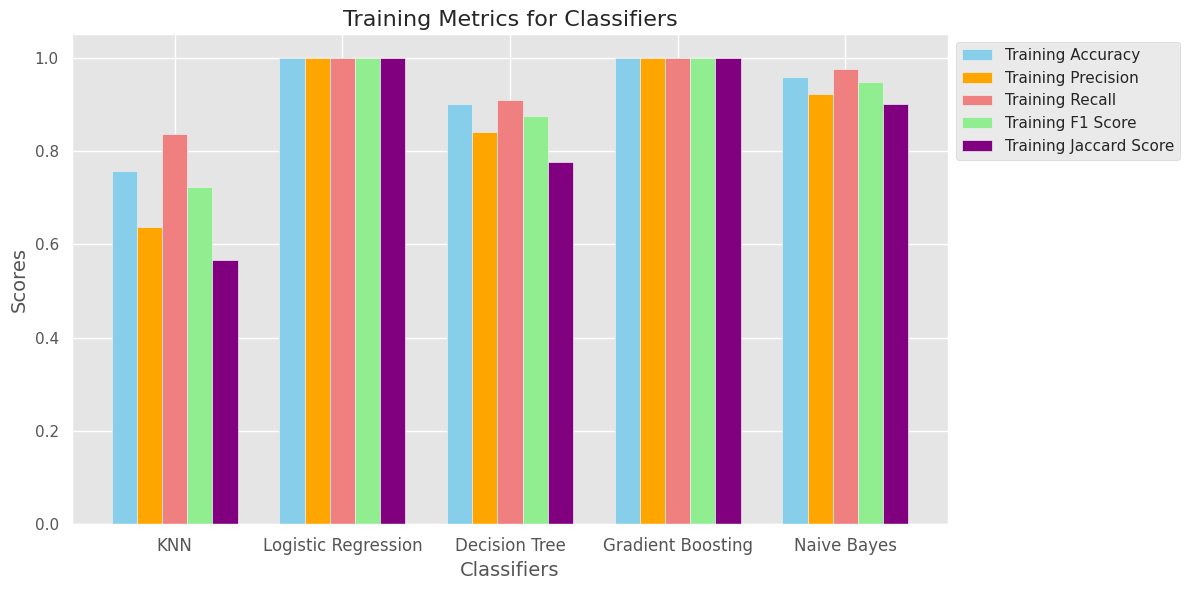

In [ ]:

# Metrics extracted from the uploaded file
classifiers = ['KNN', 'Logistic Regression', 'Decision Tree', 'Gradient Boosting', 'Naive Bayes']
training_accuracy = [0.75625, 1.0, 0.9, 1.0, 0.959375]
training_precision = [0.6375, 1.0, 0.840,1.0, 0.922]
training_recall = [0.836, 1.0, 0.909, 1.0, 0.975]
training_f1 = [0.723, 1.0, 0.874, 1.0, 0.948]
training_jaccard = [0.5666, 1.0, 0.776, 1.0, 0.9015]

x = np.arange(len(classifiers))  # the label locations
width = 0.15  # the width of the bars

fig, ax = plt.subplots(figsize=(12, 6))


# Plot training metrics
ax.bar(x - 2 * width, training_accuracy, width, label='Training Accuracy', color='skyblue')
ax.bar(x - width, training_precision, width, label='Training Precision', color='orange')
ax.bar(x, training_recall, width, label='Training Recall', color='lightcoral')
ax.bar(x + width, training_f1, width, label='Training F1 Score', color='lightgreen')
ax.bar(x + 2 * width, training_jaccard, width, label='Training Jaccard Score', color='purple')


# Add labels and title
ax.set_xlabel('Classifiers', fontsize=14)
ax.set_ylabel('Scores', fontsize=14)
ax.set_title('Training Metrics for Classifiers', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(classifiers, fontsize=12)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

# Improve layout and display
fig.tight_layout()
plt.show()


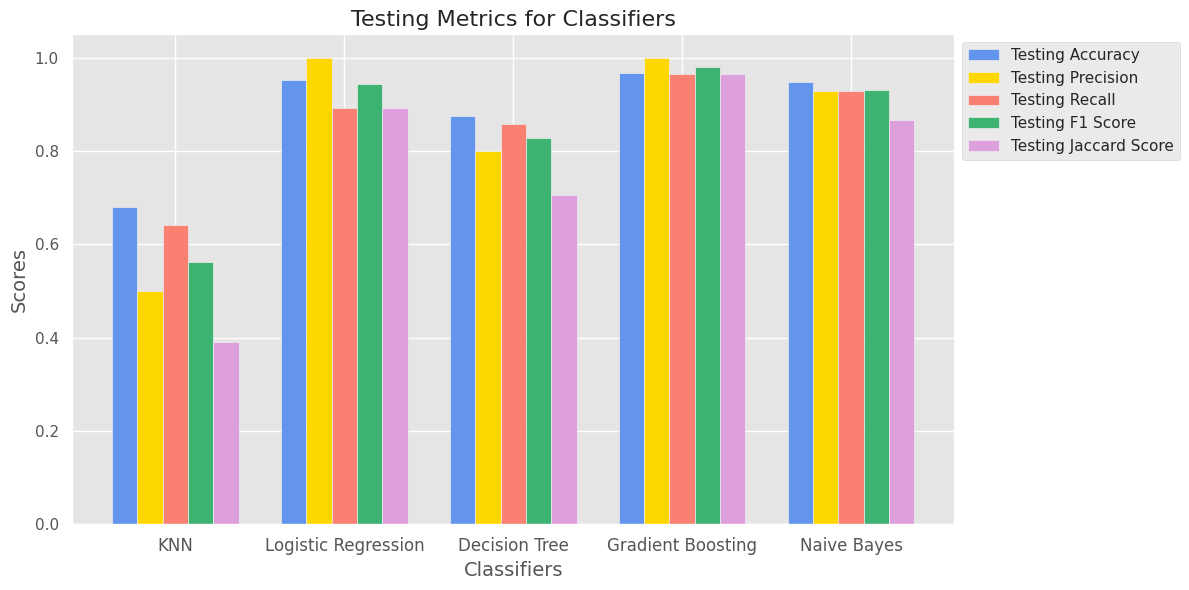

In [ ]:

# Metrics extracted from the uploaded file
classifiers = ['KNN', 'Logistic Regression', 'Decision Tree', 'Gradient Boosting', 'Naive Bayes']
testing_accuracy = [0.68, 0.9525,0.875, 0.9675, 0.9475 ]
testing_precision = [0.5, 1.0, 0.8, 1.0, 0.928 ]
testing_recall = [0.642, 0.892, 0.857, 0.964, 0.928 ]
testing_f1 = [0.5625, 0.9433, 0.827, 0.981, 0.93 ]
testing_jaccard = [0.391, 0.892, 0.705, 0.964, 0.866 ]

x = np.arange(len(classifiers))  # the label locations
width = 0.15  # the width of the bars

fig, ax = plt.subplots(figsize=(12, 6))


# Plot training metrics
ax.bar(x - 2 * width, testing_accuracy, width, label='Testing Accuracy', color='cornflowerblue')
ax.bar(x - width, testing_precision, width, label='Testing Precision', color='gold')
ax.bar(x, testing_recall, width, label='Testing Recall', color='salmon')
ax.bar(x + width, testing_f1, width, label='Testing F1 Score', color='mediumseagreen')
ax.bar(x + 2 * width, testing_jaccard, width, label='Testing Jaccard Score', color='plum')


# Add labels and title
ax.set_xlabel('Classifiers', fontsize=14)
ax.set_ylabel('Scores', fontsize=14)
ax.set_title('Testing Metrics for Classifiers', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(classifiers, fontsize=12)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

# Improve layout and display
fig.tight_layout()
plt.show()


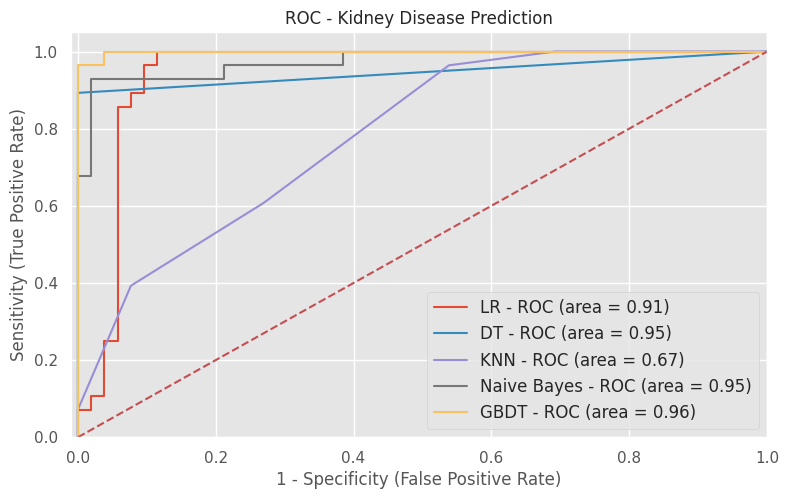

In [ ]:
from sklearn import metrics
plt.figure(figsize=(8,5))
models = [
{
    'label': 'LR',
    'model': lr,
},
{
    'label': 'DT',
    'model': dtc,
},
{
    'label': 'KNN',
    'model': knn,
},
{
    'label': 'Naive Bayes',
    'model': nb,
},
{
    'label': 'GBDT',
    'model': gbc,
}
]
for m in models:
    model = m['model']
    model.fit(X_train, y_train)
    y_pred=model.predict(X_test)
    fpr1, tpr1, thresholds = metrics.roc_curve(y_test, model.predict_proba(X_test)[:,1])
    auc = metrics.roc_auc_score(y_test,model.predict(X_test))
    plt.plot(fpr1, tpr1, label='%s - ROC (area = %0.2f)' % (m['label'], auc))

plt.plot([0, 1], [0, 1],'r--')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('1 - Specificity (False Positive Rate)', fontsize=12)
plt.ylabel('Sensitivity (True Positive Rate)', fontsize=12)
plt.title('ROC - Kidney Disease Prediction', fontsize=12)
plt.legend(loc="lower right", fontsize=12)
plt.savefig("roc_kidney.jpeg", format='jpeg', dpi=400, bbox_inches='tight')
plt.show()

#Preprocessing Steps for optimized model

In [ ]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import LabelEncoder, StandardScaler, PowerTransformer
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.model_selection import GridSearchCV

In [ ]:
# Remove low-variance features
var_thresh = VarianceThreshold(threshold=0.01)
X = var_thresh.fit_transform(X)

# Apply Power Transformation to normalize distributions
pt = PowerTransformer()
X = pt.fit_transform(X)

# Standardize features
#scaler = StandardScaler()
#X = scaler.fit_transform(X)
random_seed = 42
# Handle class imbalance with SMOTE
smote = SMOTE(sampling_strategy=1, random_state=random_seed)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Stratified Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=random_seed, stratify=y_resampled
)

#Optimization

#KNN

In [ ]:
param_grid= {
            'n_neighbors': [3, 5, 7,9,11],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan', 'minkowski'],
            'p': [1, 2],
            'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
            'leaf_size': [10, 20, 30, 40, 50]
        }


grid_search_knn = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')
grid_search_knn.fit(X_train, y_train)

print(grid_search_knn.best_params_)
print(grid_search_knn.best_score_)
knn_opt = grid_search_knn.best_estimator_
y_pred_knn_opt = knn_opt.predict(X_test)
#y_train_pred_dtc_opt = dtc_opt.predict(X_train)
y_prob_knn_opt = knn_opt.predict_proba(X_test)[:, 1] if hasattr(knn_opt, 'predict_proba') else None


print(f"Testing Accuracy of dtc is {accuracy_score(y_test, y_pred_knn_opt)}")
print(f"Testing Precision of dtc is {precision_score(y_test, y_pred_knn_opt)}")
print(f"Testing Recall of dtc is {recall_score(y_test, y_pred_knn_opt)}")
print(f"Testing F1 score of dtc is {f1_score(y_test, y_pred_knn_opt)}")
print(f"Testing Jaccard Score of dtc is {jaccard_score(y_test, y_pred_knn_opt)}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_knn_opt) if y_prob_knn_opt is not None else None}")
print(f"Confusion Matrix of dtc is \n {confusion_matrix(y_test, knn_opt.predict(X_test))}\n")
print(f"Classification Report of dtc is \n{classification_report(y_test, knn_opt.predict(X_test))}")

{'algorithm': 'auto', 'leaf_size': 10, 'metric': 'euclidean', 'n_neighbors': 3, 'p': 1, 'weights': 'distance'}
0.915
Testing Accuracy of dtc is 0.96
Testing Precision of dtc is 0.9259259259259259
Testing Recall of dtc is 1.0
Testing F1 score of dtc is 0.9615384615384616
Testing Jaccard Score of dtc is 0.9259259259259259
Testing Roc Auc 0.98
Confusion Matrix of dtc is 
 [[46  4]
 [ 0 50]]

Classification Report of dtc is 
              precision    recall  f1-score   support

           0       1.00      0.92      0.96        50
           1       0.93      1.00      0.96        50

    accuracy                           0.96       100
   macro avg       0.96      0.96      0.96       100
weighted avg       0.96      0.96      0.96       100



#DTC

In [ ]:
dtc_parameter = {
    'criterion':['gini','entropy'],
    'max_depth':[3,5,7,10],
    'splitter':['best','random'],
    'min_samples_leaf':[1,2,3,5,7],
    'min_samples_split':[1,2,3,5,7],
    'max_features':['auto', 'sqrt', 'log2']
}

grid_search_dtc = GridSearchCV(dtc, dtc_parameter, cv=5, n_jobs=-1, verbose = 1)
grid_search_dtc.fit(X_train, y_train)
print(grid_search_dtc.best_params_)
print(grid_search_dtc.best_score_)
dtc_opt = grid_search_dtc.best_estimator_
y_pred_dtc_opt = dtc_opt.predict(X_test)
#y_train_pred_dtc_opt = dtc_opt.predict(X_train)
y_prob_dtc_opt = dtc_opt.predict_proba(X_test)[:, 1] if hasattr(dtc_opt, 'predict_proba') else None

#print(f"Training Accuracy of DTC is {accuracy_score(y_train, y_train_pred_dtc_opt)}")
print(f"Testing Accuracy of dtc is {accuracy_score(y_test, y_pred_dtc_opt)}")
#print(f"Training Precision of dtc is {precision_score(y_train, y_train_pred_dtc)}")
#print(f"Training Recall of dtc is {recall_score(y_train, y_train_pred_dtc)}")
#print(f"Training F1 score of dtc is {f1_score(y_train, y_train_pred_dtc)}")
#print(f"Training Jaccard of dtc is {jaccard_score(y_train, y_train_pred_dtc)}")
print(f"Testing Precision of dtc is {precision_score(y_test, y_pred_dtc_opt)}")
print(f"Testing Recall of dtc is {recall_score(y_test, y_pred_dtc_opt)}")
print(f"Testing F1 score of dtc is {f1_score(y_test, y_pred_dtc_opt)}")
print(f"Testing Jaccard Score of dtc is {jaccard_score(y_test, y_pred_dtc_opt)}")
#print(f"Training Roc Auc {roc_auc_score(y_train, dtc.predict_proba(X_train)[:, 1]) if hasattr(dtc, 'predict_proba') else None}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_dtc_opt) if y_prob_dtc_opt is not None else None}")
print(f"Confusion Matrix of dtc is \n {confusion_matrix(y_test, dtc_opt.predict(X_test))}\n")
print(f"Classification Report of dtc is \n{classification_report(y_test, dtc_opt.predict(X_test))}")

Fitting 5 folds for each of 1200 candidates, totalling 6000 fits
{'criterion': 'gini', 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 5, 'min_samples_split': 5, 'splitter': 'best'}
0.9724999999999999
Testing Accuracy of dtc is 0.98
Testing Precision of dtc is 0.9615384615384616
Testing Recall of dtc is 1.0
Testing F1 score of dtc is 0.9803921568627451
Testing Jaccard Score of dtc is 0.9615384615384616
Testing Roc Auc 0.9992
Confusion Matrix of dtc is 
 [[48  2]
 [ 0 50]]

Classification Report of dtc is 
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        50
           1       0.96      1.00      0.98        50

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100



#Logistic Regression

In [ ]:
param_dist = {
    'C': np.logspace(-4, 4, 20),
    'penalty': ['l1', 'l2', 'elasticnet', 'none'],
    'solver': ['liblinear', 'saga', 'lbfgs'],
    'l1_ratio': np.linspace(0, 1, 10),
    'max_iter': [100, 500, 1000, 2000]
}
grid_search_lr = GridSearchCV(
    lr,
    param_dist, # Changed from param_grid to param_dist
    cv=5,
    scoring='accuracy',
    verbose=1,
    n_jobs=-1
)
grid_search_lr.fit(X_train, y_train)

print(grid_search_lr.best_params_)
print(grid_search_lr.best_score_)
lr_opt = grid_search_lr.best_estimator_
y_pred_lr_opt = lr_opt.predict(X_test)
#y_train_pred_dtc_opt = dtc_opt.predict(X_train)
y_prob_lr_opt = lr_opt.predict_proba(X_test)[:, 1] if hasattr(lr_opt, 'predict_proba') else None


print(f"Testing Accuracy of dtc is {accuracy_score(y_test, y_pred_lr_opt)}")
print(f"Testing Precision of dtc is {precision_score(y_test, y_pred_lr_opt)}")
print(f"Testing Recall of dtc is {recall_score(y_test, y_pred_lr_opt)}")
print(f"Testing F1 score of dtc is {f1_score(y_test, y_pred_lr_opt)}")
print(f"Testing Jaccard Score of dtc is {jaccard_score(y_test, y_pred_lr_opt)}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_lr_opt) if y_prob_lr_opt is not None else None}")
print(f"Confusion Matrix of dtc is \n {confusion_matrix(y_test, lr_opt.predict(X_test))}\n")
print(f"Classification Report of dtc is \n{classification_report(y_test, lr_opt.predict(X_test))}")

Fitting 5 folds for each of 9600 candidates, totalling 48000 fits
{'C': 0.615848211066026, 'l1_ratio': 0.0, 'max_iter': 100, 'penalty': 'l2', 'solver': 'lbfgs'}
0.9724999999999999
Testing Accuracy of dtc is 0.99
Testing Precision of dtc is 0.9803921568627451
Testing Recall of dtc is 1.0
Testing F1 score of dtc is 0.9900990099009901
Testing Jaccard Score of dtc is 0.9803921568627451
Testing Roc Auc 0.9952
Confusion Matrix of dtc is 
 [[49  1]
 [ 0 50]]

Classification Report of dtc is 
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.98      1.00      0.99        50

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100



#Gradient Boosting

In [ ]:

param_grid = {
    'n_estimators': [50, 100, 200, 500],
    'learning_rate': [0.001, 0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6, 7],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.8, 0.9, 1.0],
    'max_features': ['auto', 'sqrt', 'log2'],
    'loss': ['deviance', 'exponential'],
}

grid_search_gbc = GridSearchCV(gbc, param_grid,  cv=5,   scoring='accuracy',  verbose=1, n_jobs=-1)

grid_search_gbc.fit(X_train, y_train)

print(grid_search_gbc.best_params_)
print(grid_search_gbc.best_score_)
gbc_opt = grid_search_gbc.best_estimator_
y_pred_gbc_opt = gbc_opt.predict(X_test)
#y_train_pred_dtc_opt = dtc_opt.predict(X_train)
y_prob_gbc_opt = gbc_opt.predict_proba(X_test)[:, 1] if hasattr(gbc_opt, 'predict_proba') else None


print(f"Testing Accuracy of dtc is {accuracy_score(y_test, y_pred_gbc_opt)}")
print(f"Testing Precision of dtc is {precision_score(y_test, y_pred_gbc_opt)}")
print(f"Testing Recall of dtc is {recall_score(y_test, y_pred_gbc_opt)}")
print(f"Testing F1 score of dtc is {f1_score(y_test, y_pred_gbc_opt)}")
print(f"Testing Jaccard Score of dtc is {jaccard_score(y_test, y_pred_gbc_opt)}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_gbc_opt) if y_prob_gbc_opt is not None else None}")
print(f"Confusion Matrix of dtc is \n {confusion_matrix(y_test, gbc_opt.predict(X_test))}\n")
print(f"Classification Report of dtc is \n{classification_report(y_test, gbc_opt.predict(X_test))}")

Fitting 5 folds for each of 12960 candidates, totalling 64800 fits
{'learning_rate': 0.1, 'loss': 'exponential', 'max_depth': 6, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200, 'subsample': 0.9}
0.9974999999999999
Testing Accuracy of dtc is 0.98
Testing Precision of dtc is 0.9615384615384616
Testing Recall of dtc is 1.0
Testing F1 score of dtc is 0.9803921568627451
Testing Jaccard Score of dtc is 0.9615384615384616
Testing Roc Auc 1.0
Confusion Matrix of dtc is 
 [[48  2]
 [ 0 50]]

Classification Report of dtc is 
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        50
           1       0.96      1.00      0.98        50

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100



#Naive Bayes

In [ ]:
param_grid = {
    'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],  # Smoothing parameter
    'priors': [None, [0.2, 0.8], [0.5, 0.5]]
}

# Perform Grid Search with cross-validation
grid_search_nb = GridSearchCV(
    nb,
    param_grid,
    cv=5,
    scoring='accuracy',
    verbose=1,
    n_jobs=-1
)

grid_search_nb.fit(X_train, y_train)
print(grid_search_nb.best_params_)
print(grid_search_nb.best_score_)
nb_opt = grid_search_nb.best_estimator_
y_pred_nb_opt = nb_opt.predict(X_test)
#y_train_pred_dtc_opt = dtc_opt.predict(X_train)
y_prob_nb_opt = nb_opt.predict_proba(X_test)[:, 1] if hasattr(nb_opt, 'predict_proba') else None


print(f"Testing Accuracy of dtc is {accuracy_score(y_test, y_pred_nb_opt)}")
print(f"Testing Precision of dtc is {precision_score(y_test, y_pred_nb_opt)}")
print(f"Testing Recall of dtc is {recall_score(y_test, y_pred_nb_opt)}")
print(f"Testing F1 score of dtc is {f1_score(y_test, y_pred_nb_opt)}")
print(f"Testing Jaccard Score of dtc is {jaccard_score(y_test, y_pred_nb_opt)}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_gbc_opt) if y_prob_nb_opt is not None else None}")
print(f"Confusion Matrix of dtc is \n {confusion_matrix(y_test, nb_opt.predict(X_test))}\n")
print(f"Classification Report of dtc is \n{classification_report(y_test, nb_opt.predict(X_test))}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'priors': None, 'var_smoothing': 0.1}
0.95
Testing Accuracy of dtc is 0.97
Testing Precision of dtc is 0.9433962264150944
Testing Recall of dtc is 1.0
Testing F1 score of dtc is 0.970873786407767
Testing Jaccard Score of dtc is 0.9433962264150944
Testing Roc Auc 1.0
Confusion Matrix of dtc is 
 [[47  3]
 [ 0 50]]

Classification Report of dtc is 
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        50
           1       0.94      1.00      0.97        50

    accuracy                           0.97       100
   macro avg       0.97      0.97      0.97       100
weighted avg       0.97      0.97      0.97       100



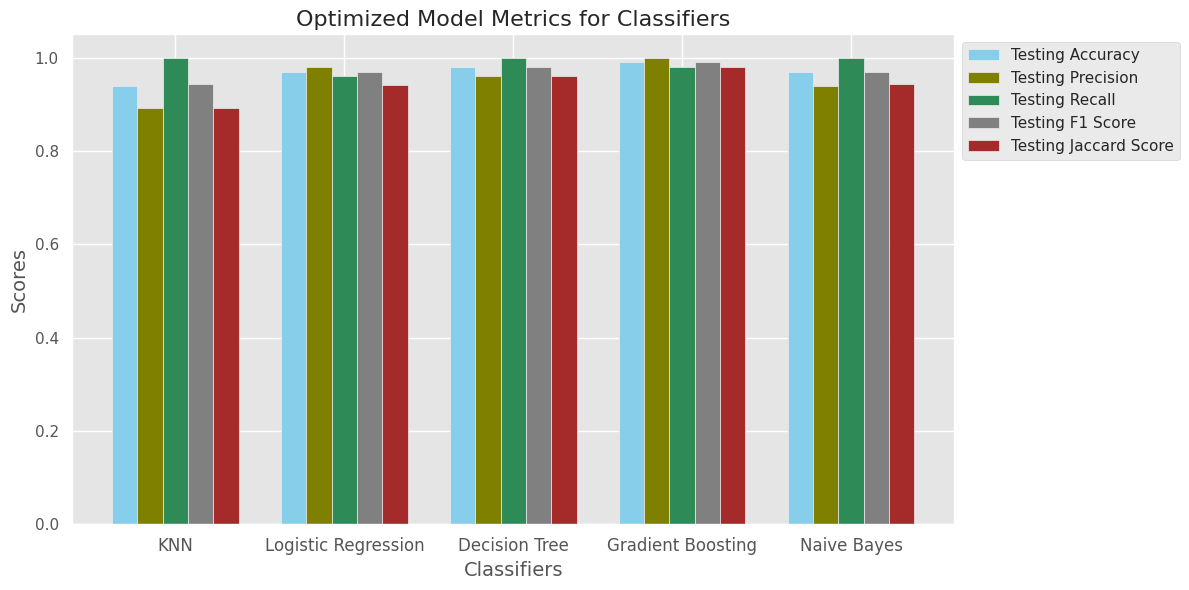

In [ ]:
# Metrics extracted from the uploaded file
classifiers = ['KNN', 'Logistic Regression', 'Decision Tree', 'Gradient Boosting', 'Naive Bayes']
testing_accuracy = [ 0.94,0.97, 0.98, 0.99, 0.97, ]
testing_precision = [0.892, 0.979, 0.96, 1.0, 0.94, ]
testing_recall = [1.0, 0.96, 1.0,0.98, 1.0,  ]
testing_f1 = [0.943,0.969, 0.980, 0.99,0.970, ]
testing_jaccard = [0.892,0.941, 0.96, 0.98, 0.943 ]

x = np.arange(len(classifiers))  # the label locations
width = 0.15  # the width of the bars

fig, ax = plt.subplots(figsize=(12, 6))


# Plot training metrics
ax.bar(x - 2 * width, testing_accuracy, width, label='Testing Accuracy', color='skyblue')
ax.bar(x - width, testing_precision, width, label='Testing Precision', color='olive')
ax.bar(x, testing_recall, width, label='Testing Recall', color='seagreen')
ax.bar(x + width, testing_f1, width, label='Testing F1 Score', color='gray')
ax.bar(x + 2 * width, testing_jaccard, width, label='Testing Jaccard Score', color='brown')


# Add labels and title
ax.set_xlabel('Classifiers', fontsize=14)
ax.set_ylabel('Scores', fontsize=14)
ax.set_title('Optimized Model Metrics for Classifiers', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(classifiers, fontsize=12)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

# Improve layout and display
fig.tight_layout()
plt.show()

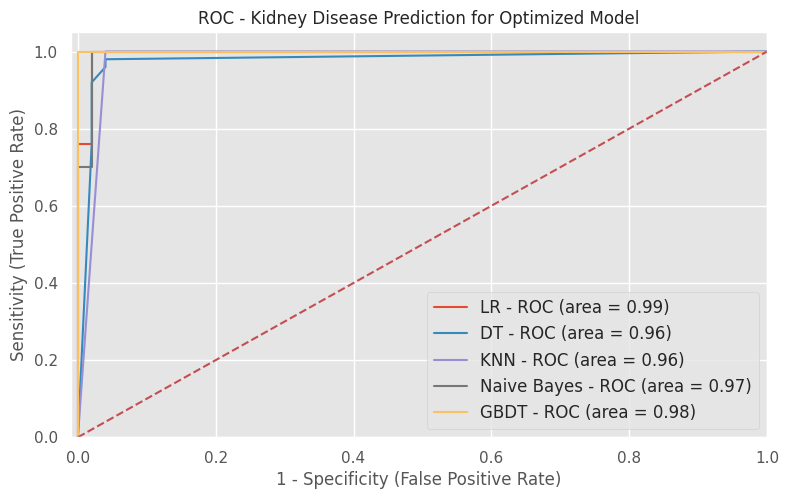

In [ ]:
from sklearn import metrics
plt.figure(figsize=(8,5))
models = [
{
    'label': 'LR',
    'model': lr_opt,
},
{
    'label': 'DT',
    'model': dtc_opt,
},
{
    'label': 'KNN',
    'model': knn_opt,
},
{
    'label': 'Naive Bayes',
    'model': nb_opt,
},
{
    'label': 'GBDT',
    'model': gbc_opt,
}
]
for m in models:
    model = m['model']
    model.fit(X_train, y_train)
    y_pred=model.predict(X_test)
    fpr1, tpr1, thresholds = metrics.roc_curve(y_test, model.predict_proba(X_test)[:,1])
    auc = metrics.roc_auc_score(y_test,model.predict(X_test))
    plt.plot(fpr1, tpr1, label='%s - ROC (area = %0.2f)' % (m['label'], auc))

plt.plot([0, 1], [0, 1],'r--')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('1 - Specificity (False Positive Rate)', fontsize=12)
plt.ylabel('Sensitivity (True Positive Rate)', fontsize=12)
plt.title('ROC - Kidney Disease Prediction for Optimized Model', fontsize=12)
plt.legend(loc="lower right", fontsize=12)
plt.savefig("roc_kidney_optimized.jpeg", format='jpeg', dpi=400, bbox_inches='tight')
plt.show()

#Hybrid Model

-NB [ Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'priors': None, 'var_smoothing': 0.1}]

- GB [{'learning_rate': 0.001, 'loss': 'exponential', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50, 'subsample': 1.0}]
- LR [ {'C': 0.23357214690901212, 'l1_ratio': 0.0, 'max_iter': 100, 'penalty': 'l2', 'solver': 'saga'}]
- dtc [ {'criterion': 'gini', 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 3, 'splitter': 'best'}]
- knn [ {'algorithm': 'auto', 'leaf_size': 10, 'metric': 'manhattan', 'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}]

In [ ]:
from sklearn.ensemble import StackingClassifier

In [ ]:
base_models = [
    ('LogisticRegression', LogisticRegression(C=0.23357214690901212, l1_ratio=0.0, max_iter=100, penalty='l2', solver='saga')),
    ('NaiveBayes', GaussianNB(priors=None, var_smoothing=0.1)),
    ('GradientBoosting', GradientBoostingClassifier(learning_rate=0.001, loss='exponential', max_depth=5, max_features='sqrt', min_samples_leaf=2, min_samples_split=2, n_estimators=50, subsample=1.0))
]

meta_model = LogisticRegression(C=0.23357214690901212, l1_ratio=0.0, max_iter=100, penalty='l2', solver='saga')

stacking_model = StackingClassifier(estimators=base_models, final_estimator=meta_model, cv=5, n_jobs=-1)

stacking_model.fit(X_train, y_train)

y_pred_stack = stacking_model.predict(X_test)
#y_train_pred_dtc_opt = dtc_opt.predict(X_train)
y_prob_hyb = nb_opt.predict_proba(X_test)[:, 1] if hasattr(stacking_model, 'predict_proba') else None


print(f"Testing Accuracy of hyb is {accuracy_score(y_test, y_pred_stack)}")
print(f"Testing Precision of hyb is {precision_score(y_test, y_pred_stack)}")
print(f"Testing Recall of hyb is {recall_score(y_test, y_pred_stack)}")
print(f"Testing F1 score of hyb is {f1_score(y_test, y_pred_stack)}")
print(f"Testing Jaccard Score of hyb is {jaccard_score(y_test, y_pred_stack)}")
print(f"Testing Roc Auc {roc_auc_score(y_test, y_prob_hyb) if y_prob_hyb is not None else None}")
print(f"Confusion Matrix of dtc is \n {confusion_matrix(y_test, stacking_model.predict(X_test))}\n")
print(f"Classification Report of dtc is \n{classification_report(y_test, stacking_model.predict(X_test))}")



Testing Accuracy of hyb is 0.99
Testing Precision of hyb is 0.9803921568627451
Testing Recall of hyb is 1.0
Testing F1 score of hyb is 0.9900990099009901
Testing Jaccard Score of hyb is 0.9803921568627451
Testing Roc Auc 0.994
Confusion Matrix of dtc is 
 [[49  1]
 [ 0 50]]

Classification Report of dtc is 
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        50
           1       0.98      1.00      0.99        50

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100



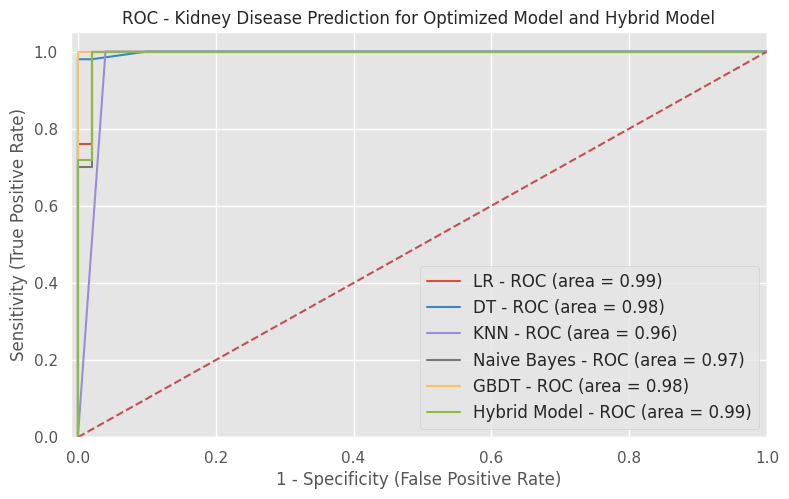

In [ ]:
from sklearn import metrics
plt.figure(figsize=(8,5))
models = [
{
    'label': 'LR',
    'model': lr_opt,
},
{
    'label': 'DT',
    'model': dtc_opt,
},
{
    'label': 'KNN',
    'model': knn_opt,
},
{
    'label': 'Naive Bayes',
    'model': nb_opt,
},
{
    'label': 'GBDT',
    'model': gbc_opt,
},
   {
    'label': 'Hybrid Model',
    'model': stacking_model,
}
]
for m in models:
    model = m['model']
    model.fit(X_train, y_train)
    y_pred=model.predict(X_test)
    fpr1, tpr1, thresholds = metrics.roc_curve(y_test, model.predict_proba(X_test)[:,1])
    auc = metrics.roc_auc_score(y_test,model.predict(X_test))
    plt.plot(fpr1, tpr1, label='%s - ROC (area = %0.2f)' % (m['label'], auc))

plt.plot([0, 1], [0, 1],'r--')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('1 - Specificity (False Positive Rate)', fontsize=12)
plt.ylabel('Sensitivity (True Positive Rate)', fontsize=12)
plt.title('ROC - Kidney Disease Prediction for Optimized Model and Hybrid Model', fontsize=12)
plt.legend(loc="lower right", fontsize=12)
plt.savefig("roc_kidney_optimized.jpeg", format='jpeg', dpi=400, bbox_inches='tight')
plt.show()

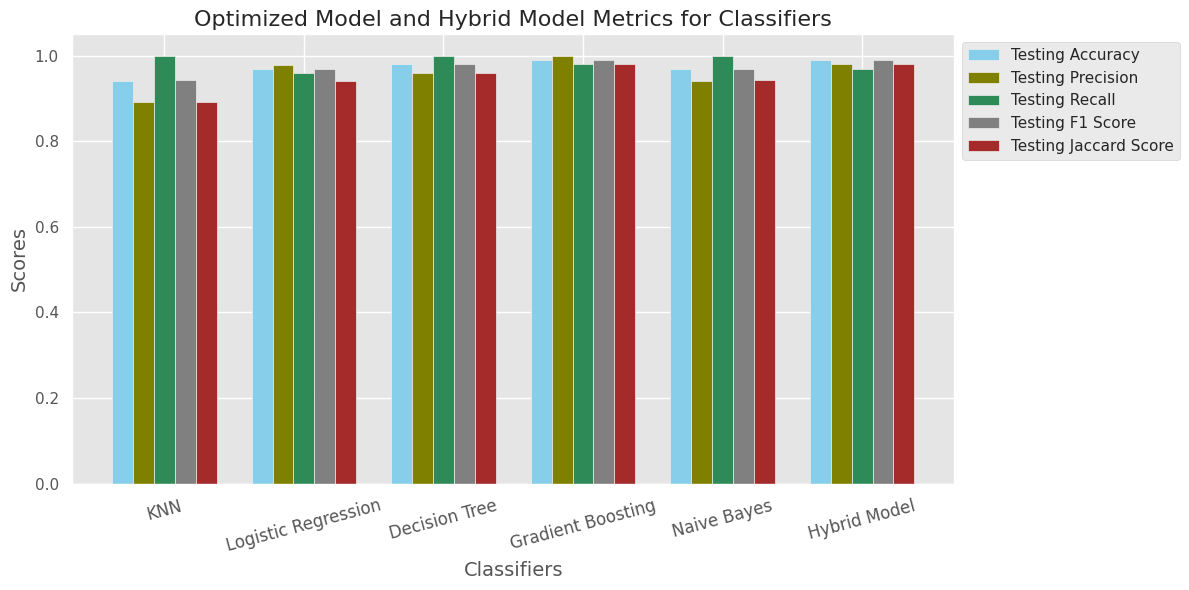

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Classifiers and their corresponding metrics
classifiers = ['KNN', 'Logistic Regression', 'Decision Tree', 'Gradient Boosting', 'Naive Bayes', 'Hybrid Model']
testing_accuracy = [0.94, 0.97, 0.98, 0.99, 0.97, 0.99]
testing_precision = [0.892, 0.979, 0.96, 1.0, 0.94, 0.980]
testing_recall = [1.0, 0.96, 1.0, 0.98, 1.0, 0.97]
testing_f1 = [0.943, 0.969, 0.980, 0.99, 0.970, 0.990]
testing_jaccard = [0.892, 0.941, 0.96, 0.98, 0.943, 0.980]

x = np.arange(len(classifiers))  # Label locations
width = 0.15  # Bar width

fig, ax = plt.subplots(figsize=(12, 6))

# Plot testing metrics
ax.bar(x - 2 * width, testing_accuracy, width, label='Testing Accuracy', color='skyblue')
ax.bar(x - width, testing_precision, width, label='Testing Precision', color='olive')
ax.bar(x, testing_recall, width, label='Testing Recall', color='seagreen')
ax.bar(x + width, testing_f1, width, label='Testing F1 Score', color='gray')
ax.bar(x + 2 * width, testing_jaccard, width, label='Testing Jaccard Score', color='brown')

# Labels and title
ax.set_xlabel('Classifiers', fontsize=14)
ax.set_ylabel('Scores', fontsize=14)
ax.set_title('Optimized Model and Hybrid Model Metrics for Classifiers', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(classifiers, fontsize=12, rotation=15)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

# Improve layout and display
fig.tight_layout()
plt.show()


In [ ]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 9.7 MB 985 kB/s eta 0:00:01
     |████████████████████████████████| 451 kB 6.4 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset shape:")
print(df.shape)

print("\nFirst 3 rows:")
display(df.head(3))

Columns:
['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium', 'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count', 'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema', 'aanemia', 'class']

Dataset shape:
(400, 25)

First 3 rows:


,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.02,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,0
1,7.0,50.0,1.02,4.0,0.0,0,1,0,0,176.0,...,38.0,6000.0,5.6,0,0,0,0,0,0,0
2,62.0,80.0,1.01,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.5,0,1,0,1,0,1,0
